In [30]:
import h5py
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.cm as cm



import scienceplots
plt.style.use(['science', 'no-latex'])


from pybaselines import Baseline, utils 
from scipy.signal import find_peaks
from astropy.stats import median_absolute_deviation as MAD
from astropy.stats import mad_std 
from astropy.modeling import models, fitting
from astropy.convolution import convolve_models


# Select the hdf5 file

In [2]:
filename = ('/home/chavango/Master/DATA/SKAMPI_data/EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5')



# Let's porint the structure of the hdf5 file
def print_hdf5_structure(name, obj):
    indent = '  ' * name.count('/')
    if isinstance(obj, h5py.Group):
        print(f"{indent}Group: {name}")
    elif isinstance(obj, h5py.Dataset):
        print(f"{indent}Dataset: {name}, Shape: {obj.shape}, Dtype: {obj.dtype}")

with h5py.File(filename, "r") as f:

    f.visititems(print_hdf5_structure)

    f.close()  # close the file

Dataset: history, Shape: (9,), Dtype: [('processingtime', 'S23'), ('software', 'S256'), ('version', 'S128'), ('comment', 'S256')]
Group: monitor
  Group: monitor/acu
    Dataset: monitor/acu/actual_timestamp, Shape: (2650,), Dtype: float64
    Group: monitor/acu/ambient_temp_correction_config
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_1, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_10, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_2, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_3, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_4, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_5a, Shape: (2650,), Dtype: float64
      Dataset:

In [3]:
# Select different group off the data
groups = [
    "scan/000/P1_ND0",
    "scan/000/P1_ND1",
    "scan/001/P0_ND0",
    "scan/001/P0_ND1",
    "scan/001/P1_ND0",
    "scan/001/P1_ND1"
]

# Convert the hdf5 file to xarray dataset

In [ ]:

datasets = []

with h5py.File(filename, 'r') as f:
    for g in groups:
        
        # Load datasets correctly
        spectrum  = f[f"{g}/spectrum"][30:,1750:-60]       # shape (n_time, n_freq)
        frequency = f[f"{g}/frequency"][1750:-60]/ 1e9
        time      = f[f"{g}/timestamp"][30:,0]     # often 2D


        # Construct xarray dataset
        ds = xr.Dataset(
            {
                "spectrum": (("time", "frequency"), spectrum)
            },
            coords={
                "time": time,
                "frequency": frequency
            },
            attrs={
                "description": f"Spectrum data of {g}",
                "units": {
                    "spectrum": "dB",
                    "frequency": "GHz",
                    "time": "UTC"
                }
            }
        )

        ds = ds.expand_dims({"group": [g]})  # add group dimension

        datasets.append(ds)
    f.close() # close the file

datasets

[<xarray.Dataset> Size: 162MB
 Dimensions:    (group: 1, time: 634, frequency: 63727)
 Coordinates:
   * group      (group) object 8B 'scan/000/P1_ND0'
   * time       (time) float64 5kB 1.679e+09 1.679e+09 ... 1.679e+09 1.679e+09
   * frequency  (frequency) float64 510kB 1.797 1.797 1.797 ... 3.498 3.498 3.498
 Data variables:
     spectrum   (group, time, frequency) float32 162MB 1.675e+11 ... 4.159e+09
 Attributes:
     description:  Spectrum data of scan/000/P1_ND0
     units:        {'spectrum': 'dB', 'frequency': 'GHz', 'time': 'UTC'},
 <xarray.Dataset> Size: 162MB
 Dimensions:    (group: 1, time: 634, frequency: 63727)
 Coordinates:
   * group      (group) object 8B 'scan/000/P1_ND1'
   * time       (time) float64 5kB 1.679e+09 1.679e+09 ... 1.679e+09 1.679e+09
   * frequency  (frequency) float64 510kB 1.797 1.797 1.797 ... 3.498 3.498 3.498
 Data variables:
     spectrum   (group, time, frequency) float32 162MB 6.486e+10 ... 1.648e+09
 Attributes:
     description:  Spectrum da

In [ ]:
frequency[0]

In [5]:
# datasets1 = []

# with h5py.File(filename, 'r') as f:
#     for g in groups:
        
#         # Load datasets correctly
#         spectrum  = f[f"{g}/spectrum"][30:,1600:-60]       # shape (n_time, n_freq)
#         frequency = f[f"{g}/frequency"][1600:-60]/ 1e9
#         time      = f[f"{g}/timestamp"][30:,0]     # often 2D


#         # Construct xarray dataset
#         ds = xr.Dataset(
#             {
#                 "spectrum": (("time", "frequency"), spectrum)
#             },
#             coords={
#                 "time": time,
#                 "frequency": frequency
#             },
#             attrs={
#                 "description": f"Spectrum data of {g}",
#                 "units": {
#                     "spectrum": "dB",
#                     "frequency": "GHz",
#                     "time": 'ns'
#                 }
#             }
#         )

#         ds = ds.expand_dims({"group": [g]})  # add group dimension

#         datasets1.append(ds)
#     f.close() # close the file

# # Combine all datasets along the new 'group' dimension
# #combined_ds1 = xr.concat(datasets1, dim="group")

# datasets1[0]

# Selec a group off the data and visualize

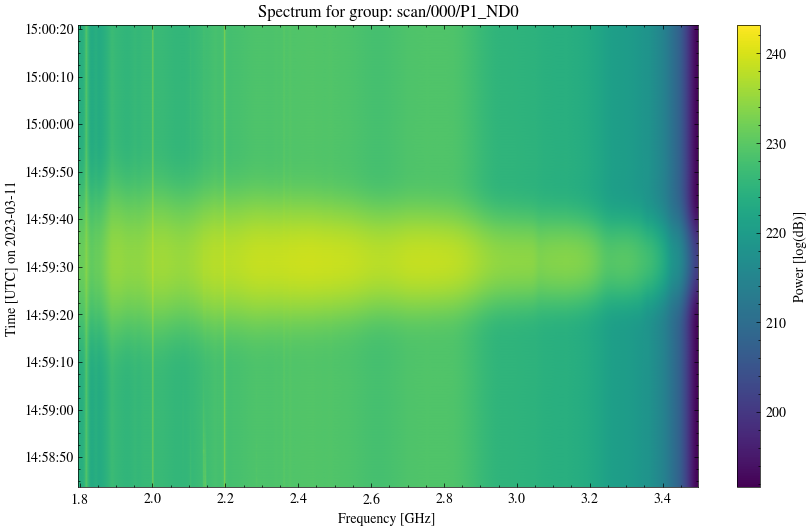

In [6]:
# selec different group off the data

for i,g in enumerate(datasets):
    spectrum = (10* np.log10(datasets[i]['spectrum']**2)).values[0,:,:]
    frequency = datasets[i]['frequency'].values
    time = datasets[i]['time'].values


    #convert time to UTC 
    time_utc = pd.to_datetime(time, unit='s', utc=True)
    time_utc = time_utc.values  # convert to numpy datetime64[ns]

    plt.figure(figsize=(10, 6))

    plt.imshow(spectrum,
                aspect='auto',
                origin='lower',
                extent=[frequency.min(), frequency.max(), time_utc.min(), time_utc.max()],
                cmap='viridis')

    plt.colorbar(label='Power [log(dB)]')



   # --- Formatting the time axis ---
    t0=pd.to_datetime(time_utc[0]).strftime('%Y-%m-%d')

    plt.title(f'Spectrum for group: {datasets[i].group.values[0]}')
    plt.xlabel('Frequency [GHz] ')
    plt.ylabel(f'Time [UTC] on {t0} ')
    plt.show()

    break

In [7]:
frequency

array([1.79671669, 1.79674339, 1.7967701 , ..., 3.49833107, 3.49835777,
       3.49838448], shape=(63727,))

In [8]:
time_utc

array(['2023-03-11T14:58:43.686180592', '2023-03-11T14:58:43.839572191',
       '2023-03-11T14:58:43.992964029', '2023-03-11T14:58:44.146355629',
       '2023-03-11T14:58:44.299747229', '2023-03-11T14:58:44.453139067',
       '2023-03-11T14:58:44.606530666', '2023-03-11T14:58:44.759922504',
       '2023-03-11T14:58:44.913314104', '2023-03-11T14:58:45.066705704',
       '2023-03-11T14:58:45.220097542', '2023-03-11T14:58:45.373489141',
       '2023-03-11T14:58:45.526880741', '2023-03-11T14:58:45.680272579',
       '2023-03-11T14:58:45.833664179', '2023-03-11T14:58:45.987056017',
       '2023-03-11T14:58:46.140447617', '2023-03-11T14:58:46.293839216',
       '2023-03-11T14:58:46.447231054', '2023-03-11T14:58:46.600622654',
       '2023-03-11T14:58:46.754014254', '2023-03-11T14:58:46.907406092',
       '2023-03-11T14:58:47.060797691', '2023-03-11T14:58:47.214189529',
       '2023-03-11T14:58:47.367581129', '2023-03-11T14:58:47.520972729',
       '2023-03-11T14:58:47.674364567', '2023-03-11

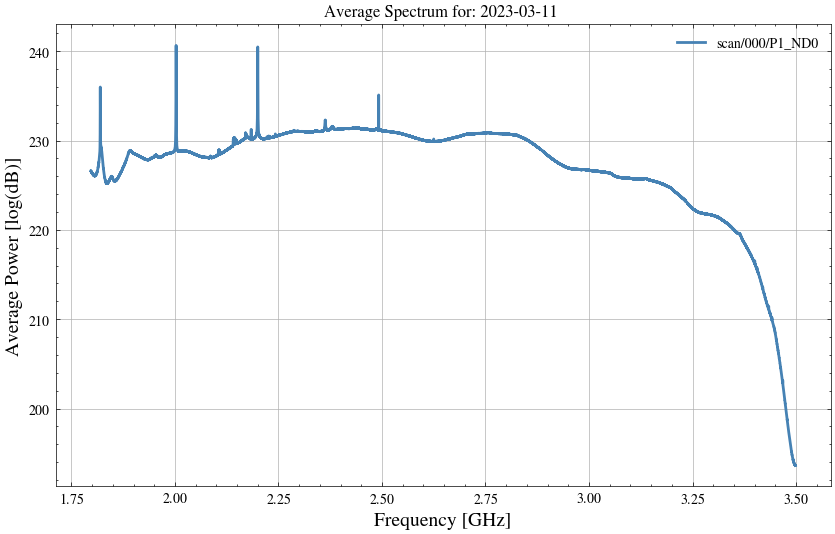

In [9]:
# Plot the average espectrum over time versus frequency 

for i,g in enumerate(datasets):
    avg_spectrum = (10* np.log10(datasets[i]['spectrum']**2)).mean(dim='time').values[0,:]

    plt.figure(figsize=(10, 6))
    plt.plot(frequency, avg_spectrum, color='steelblue', lw=2, label=f'{datasets[i].group.values[0]}')
    plt.title(f'Average Spectrum for: {t0} ')
    plt.xlabel('Frequency [GHz]',fontsize=14)
    plt.ylabel('Average Power [log(dB)]',fontsize=14)
    plt.legend()
    plt.grid()

    break



# Detrend the spectrum data by removing the baseline trend


In [10]:

# Baseline correction

def base_correction(freq,power):
    """ 
    The function perform the baseline correction using the method: "Asymmetric Least Squer"

    Takes as entries:
    --------
    freq: array
    power: array

    Returns:
    ------
    The signal with the baseline corrected
    
    """

    # Step 1: define the baseli fitting
    baseline_fitter = Baseline(x_data=freq)
    bkg, params = baseline_fitter.asls(power, lam=1e7, p=0.02)

    # Step 2: Substract the baseline
    correct_baseline = power - bkg

    return correct_baseline



## Peak detection

Detected peak > 1σ are frequencies (GHz): ['1.8196', '2.0028', '2.1064', '2.1421', '2.1459', '2.1703', '2.1707', '2.1841', '2.1845', '2.1849', '2.1999', '2.3629', '2.4920']
Detected peak > 3σ are frequencies (GHz): ['1.8196', '2.0028', '2.1841', '2.1999', '2.3629', '2.4920']


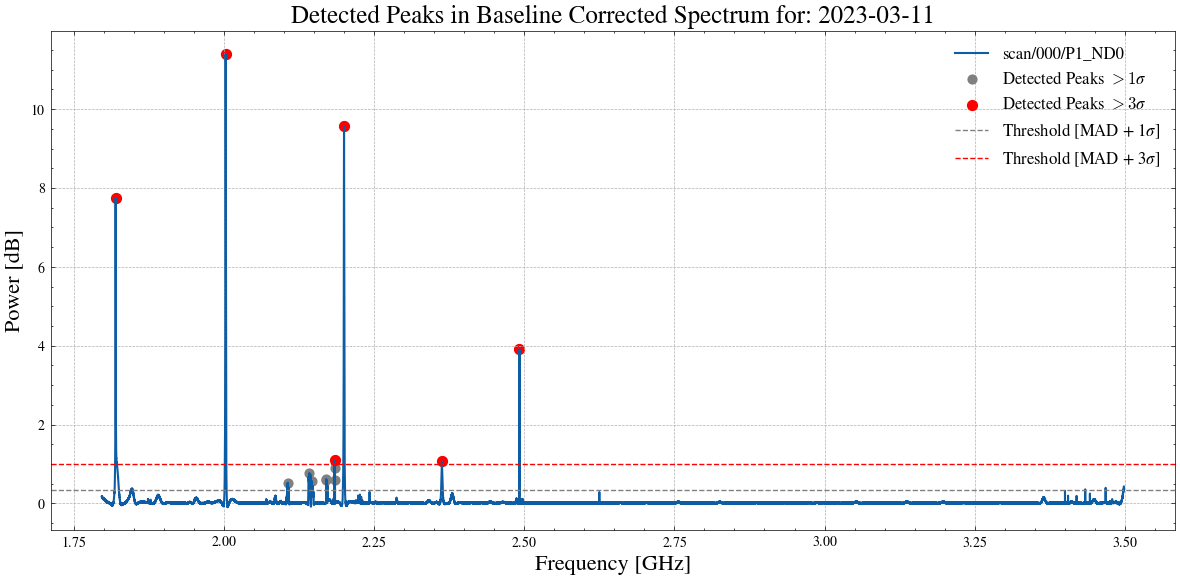

In [ ]:
# # Base line corrected and peaks detection
for i,g in enumerate(datasets):
    
    avg_spectrum = (10* np.log10(datasets[i]['spectrum']**2)).mean(dim='time').values[0,:]
    detrended_spectrum = base_correction(frequency, avg_spectrum)

    
        
    # Find peaks above 1 sigma from the MAD
    peaks, propreties = find_peaks(detrended_spectrum, 
                                height=MAD(detrended_spectrum) + np.std(detrended_spectrum),
                                distance=10,
                                prominence=0.5
                                )
    # Find peaks above 3 sigma from the MAD
    peaks1, propreties1 = find_peaks(detrended_spectrum, 
                                height=MAD(detrended_spectrum) + 3*np.std(detrended_spectrum),
                                distance=10,
                                prominence=0.5
                                )

    plt.figure(figsize=(12, 6))

    # --- Plot baseline-corrected spectrum ---
    plt.plot(frequency, detrended_spectrum, label=f'{datasets[i].group.values[0]}', lw=1.5)

    # --- Plot detected peaks ---
    plt.scatter(frequency[peaks], detrended_spectrum[peaks], 
                color='gray', s=40, label='Detected Peaks $> 1σ$')

    plt.scatter(frequency[peaks1], detrended_spectrum[peaks1], 
                color='red', s=50, label='Detected Peaks $> 3σ$')

    # --- Plot threshold lines ---
    plt.axhline(y=MAD(detrended_spectrum) + np.std(detrended_spectrum), 
                color='gray', linestyle='--', label='Threshold [MAD + 1$σ$]')

    plt.axhline(y=MAD(detrended_spectrum) + 3*np.std(detrended_spectrum), 
            color='red', linestyle='--', label='Threshold [MAD + 3$σ$]')

    # --- Labels and formatting ---
    plt.xlabel("Frequency [GHz]",fontsize=16)
    plt.ylabel("Power [dB]",fontsize=16)
    plt.title(f"Detected Peaks in Baseline Corrected Spectrum for: {t0}", fontsize=18)
    plt.grid(True, linestyle='--')
    plt.legend(fontsize=12)
    plt.tight_layout()

   #plt.savefig(f'/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/Detected_Peaks_base_cor.png', dpi=300)
   #plt.savefig(f'/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/Detected_Peaks_base_cor.pdf', dpi=300)


    # --- Print detected peak frequencies ---
    formatted_freqs = [f"{f:.4f}" for f in frequency[peaks]]
    formatted_freqs1 = [f"{f:.4f}" for f in frequency[peaks1]]

    print(f"Detected peak > 1σ are frequencies (GHz): {formatted_freqs}")
    print(f"Detected peak > 3σ are frequencies (GHz): {formatted_freqs1}")
    
    break


Detected peak > 1σ are frequencies (GHz): ['1.8196', '2.0028', '2.1064', '2.1421', '2.1459', '2.1703', '2.1707', '2.1841', '2.1845', '2.1849', '2.1999', '2.3629', '2.4920']
Detected peak > 3σ are frequencies (GHz): ['1.8196', '2.0028', '2.1064', '2.1421', '2.1459', '2.1703', '2.1707', '2.1841', '2.1845', '2.1849', '2.1999', '2.3629', '2.4920']


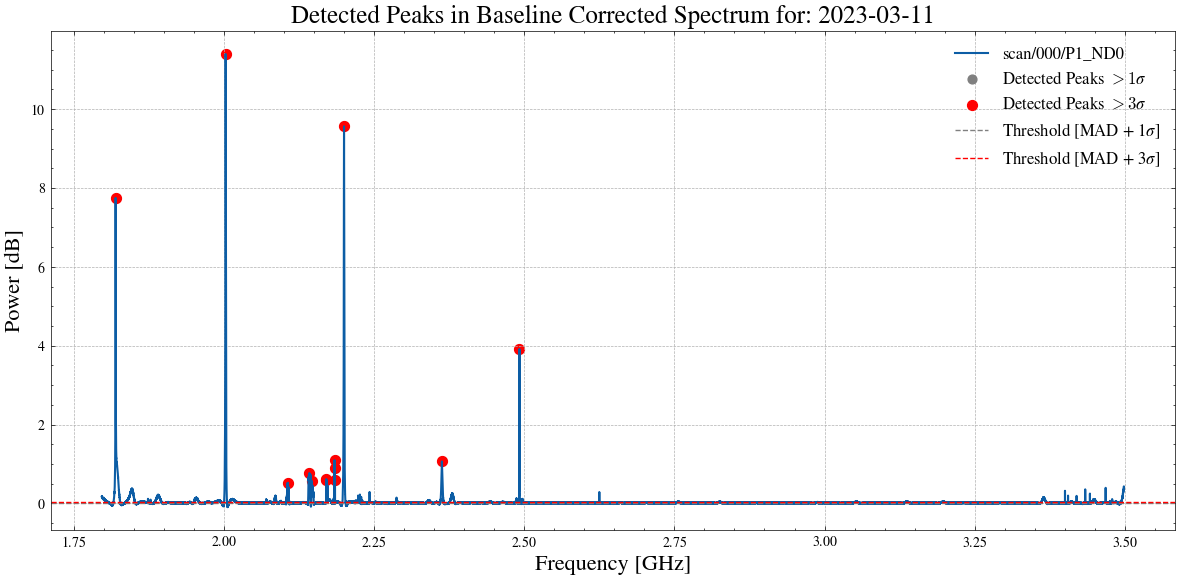

In [31]:
# # Base line corrected and peaks detection
for i,g in enumerate(datasets):
    
    avg_spectrum = (10* np.log10(datasets[i]['spectrum']**2)).mean(dim='time').values[0,:]
    detrended_spectrum = base_correction(frequency, avg_spectrum)

    sigma = mad_std(detrended_spectrum)
        
    # Find peaks above 1 sigma from the MAD
    peaks, propreties = find_peaks(detrended_spectrum, 
                                height=MAD(detrended_spectrum) + sigma,
                                distance=10,
                                prominence=0.5
                                )
    # Find peaks above 3 sigma from the MAD
    peaks1, propreties1 = find_peaks(detrended_spectrum, 
                                height=MAD(detrended_spectrum) + 3*sigma,
                                distance=10,
                                prominence=0.5
                                )

    plt.figure(figsize=(12, 6))

    # --- Plot baseline-corrected spectrum ---
    plt.plot(frequency, detrended_spectrum, label=f'{datasets[i].group.values[0]}', lw=1.5)

    # --- Plot detected peaks ---
    plt.scatter(frequency[peaks], detrended_spectrum[peaks], 
                color='gray', s=40, label='Detected Peaks $> 1σ$')

    plt.scatter(frequency[peaks1], detrended_spectrum[peaks1], 
                color='red', s=50, label='Detected Peaks $> 3σ$')

    # --- Plot threshold lines ---
    plt.axhline(y=MAD(detrended_spectrum) + sigma, 
                color='gray', linestyle='--', label='Threshold [MAD + 1$σ$]')

    plt.axhline(y=MAD(detrended_spectrum) + 3*sigma, 
            color='red', linestyle='--', label='Threshold [MAD + 3$σ$]')

    # --- Labels and formatting ---
    plt.xlabel("Frequency [GHz]",fontsize=16)
    plt.ylabel("Power [dB]",fontsize=16)
    plt.title(f"Detected Peaks in Baseline Corrected Spectrum for: {t0}", fontsize=18)
    plt.grid(True, linestyle='--')
    plt.legend(fontsize=12)
    plt.tight_layout()

   #plt.savefig(f'/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/Detected_Peaks_base_cor.png', dpi=300)
   #plt.savefig(f'/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/Detected_Peaks_base_cor.pdf', dpi=300)


    # --- Print detected peak frequencies ---
    formatted_freqs = [f"{f:.4f}" for f in frequency[peaks]]
    formatted_freqs1 = [f"{f:.4f}" for f in frequency[peaks1]]

    print(f"Detected peak > 1σ are frequencies (GHz): {formatted_freqs}")
    print(f"Detected peak > 3σ are frequencies (GHz): {formatted_freqs1}")
    
    break


Detected peak > 1σ are frequencies (GHz): ['1.8196', '2.0028', '2.1064', '2.1421', '2.1459', '2.1703', '2.1707', '2.1841', '2.1845', '2.1849', '2.1999', '2.3629', '2.4920']
Detected peak > 3σ are frequencies (GHz): ['1.8196', '2.0028', '2.1064', '2.1421', '2.1459', '2.1703', '2.1707', '2.1841', '2.1845', '2.1849', '2.1999', '2.3629', '2.4920']


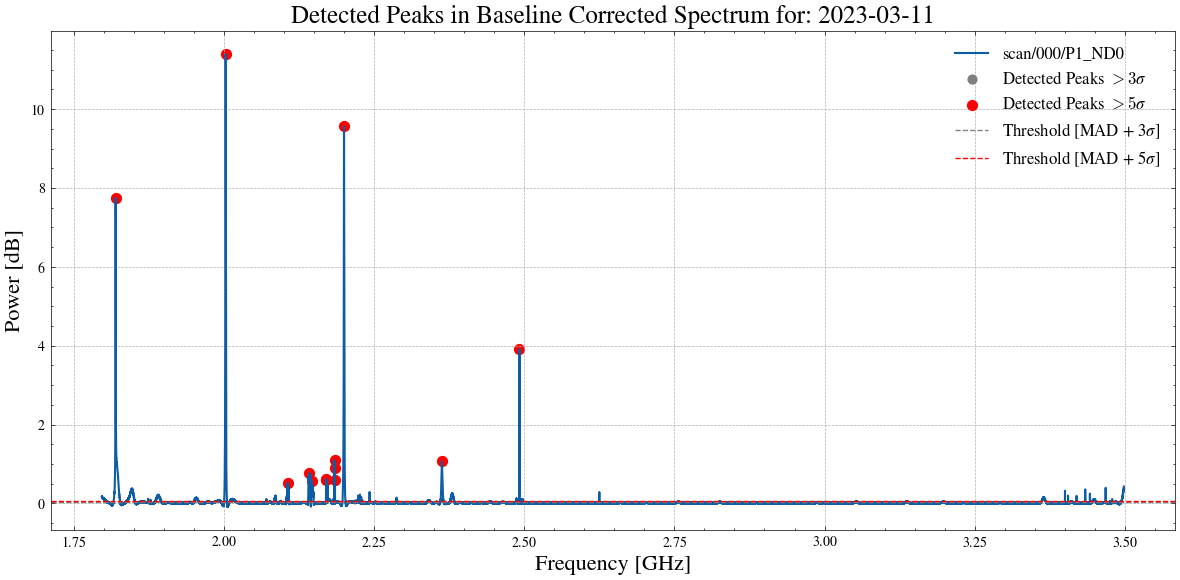

In [29]:
# # Base line corrected and peaks detection
for i,g in enumerate(datasets):
    
    avg_spectrum = (10* np.log10(datasets[i]['spectrum']**2)).mean(dim='time',skipna=True).values[0,:]
    detrended_spectrum = base_correction(frequency, avg_spectrum)

    sigma_value_high = 3
    #sigma = 1.4826*np.nanmedian(np.abs(detrended_spectrum - np.nanmedian(detrended_spectrum)))
    sigma = 1.4826*MAD(detrended_spectrum)
 
    # Find peaks above 1 sigma from the MAD
    peaks, propreties = find_peaks(detrended_spectrum, 
                                height=MAD(detrended_spectrum) + sigma_value_high*sigma,
                                distance=10,
                                prominence=0.5
                                )
    

    sigma_value_low = 5
    # Find peaks above 3 sigma from the MAD
    peaks1, propreties1 = find_peaks(detrended_spectrum, 
                                height=MAD(detrended_spectrum) + sigma_value_low*sigma,
                                distance=10,
                                prominence=0.5
                                )

    plt.figure(figsize=(12, 6))

    # --- Plot baseline-corrected spectrum ---
    plt.plot(frequency, detrended_spectrum, label=f'{datasets[i].group.values[0]}', lw=1.5)

    # --- Plot detected peaks ---
    plt.scatter(frequency[peaks], detrended_spectrum[peaks], 
                color='gray', s=40, label=f'Detected Peaks $> {sigma_value_high}σ$')

    plt.scatter(frequency[peaks1], detrended_spectrum[peaks1], 
                color='red', s=50, label=f'Detected Peaks $> {sigma_value_low}σ$')

    # --- Plot threshold lines ---
    plt.axhline(y=MAD(detrended_spectrum) + sigma_value_high*sigma, 
                color='gray', linestyle='--', label=f'Threshold [MAD + {sigma_value_high}$σ$]')

    plt.axhline(y=MAD(detrended_spectrum) + sigma_value_low*sigma, 
            color='red', linestyle='--', label=f'Threshold [MAD + {sigma_value_low}$σ$]')

    # --- Labels and formatting ---
    plt.xlabel("Frequency [GHz]",fontsize=16)
    plt.ylabel("Power [dB]",fontsize=16)
    plt.title(f"Detected Peaks in Baseline Corrected Spectrum for: {t0}", fontsize=18)
    plt.grid(True, linestyle='--')
    plt.legend(fontsize=12)
    plt.tight_layout()

   #plt.savefig(f'/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/Detected_Peaks_base_cor.png', dpi=300)
   #plt.savefig(f'/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/Detected_Peaks_base_cor.pdf', dpi=300)


    # --- Print detected peak frequencies ---
    formatted_freqs = [f"{f:.4f}" for f in frequency[peaks]]
    formatted_freqs1 = [f"{f:.4f}" for f in frequency[peaks1]]

    print(f"Detected peak > 1σ are frequencies (GHz): {formatted_freqs}")
    print(f"Detected peak > 3σ are frequencies (GHz): {formatted_freqs1}")
    
    break


# RFI characterization

In [12]:
# Characterise the RFI

def characterize_RFI_width(freq, power, tie=False, ax=None, threshold=0.05):
    """
    Characterize the frequency width and fit of an RFI peak.

    Parameters
    ----------
    freq : array-like
        Frequency values [GHz].
    power : array-like
        Baseline-corrected power spectrum (linear or dB).
    tie : bool, optional
        If True, fits two tied Gaussians (narrow + broad). 
        If False, fits a single Gaussian. Default = False.
    ax : matplotlib.axes.Axes, optional
        Existing matplotlib axis for plotting.
    threshold : float, optional
        Power threshold to define start/end of RFI. Default = 0.05.

    Returns
    -------
    results : dict
        Dictionary containing:
        - start_freq [GHz]
        - end_freq [GHz]
        - peak_freq [GHz]
        - peak_power
        - n_channels
        - bandwidth [MHz]
        - fwhm [kHz]
        - fitted_model (Astropy model)
    """

    # --- 1. Identify the RFI region above threshold ---
    above_threshold = np.where(power > threshold)[0]

    if len(above_threshold) == 0:
        print(" No significant RFI detected above threshold.")
        return None

    start_index, end_index = above_threshold[0], above_threshold[-1]
    start_freq = freq[start_index]
    end_freq = freq[end_index]

    # --- 2 Find peak position and amplitude ---
    peak_index = np.argmax(power)
    peak_freq = freq[peak_index]
    peak_power = power[peak_index]

    # --- 3 Basic RFI statistics ---
    delta_f = np.mean(np.diff(freq))  # spectral resolution
    n_channels = (end_freq - start_freq) / delta_f
    bandwidth = (end_freq - start_freq) * 1e3  # GHz → MHz

    print(f"""
          Date: {pd.to_datetime(time_utc[0]).strftime('%Y-%m-%d')}
          Start Frequency  : {start_freq:.6f} GHz 
          End Frequency    : {end_freq:.6f} GHz
          Peak Frequency   : {peak_freq:.6f} GHz  | Power = {peak_power:.3f} dB
          Corrupted Channels: {n_channels:.1f}
          Corrupted Bandwidth         : {bandwidth:.2f} MHz""")

    # --- 4 Build initial Gaussian models ---
    amp_narrow = peak_power
    sigma_narrow = 5 * delta_f  # narrow Gaussian width guess

    amp_broad = amp_narrow / 5
    sigma_broad = 0.01  # GHz-scale broad Gaussian

    g_narrow = models.Gaussian1D(amplitude=amp_narrow, mean=peak_freq, stddev=sigma_narrow)
    g_broad = models.Gaussian1D(amplitude=amp_broad, mean=peak_freq, stddev=sigma_broad)

    # --- 5 Model fitting ---
    fitter = fitting.LMLSQFitter()

    if tie:
        # Tie both Gaussian centers
        def tie_means(model):
            return model.mean_0
        g_broad.mean.tied = tie_means
        model_init = g_narrow + g_broad
        fitted_model = fitter(model_init, freq, power)
        sigma = fitted_model.stddev_0.value + fitted_model.stddev_1.value
        label = "2-Gaussian Fit (tied)"
    else:
        fitted_model = fitter(g_narrow, freq, power)
        sigma = fitted_model.stddev.value
        label = "Single Gaussian Fit"

    fwhm = 2.355 * sigma  # convert σ → FWHM
    print(f"""
          Gaussian FWHM    : {fwhm * 1e6:.2f} kHz
          Number of Channels at FWHM: {np.ceil(fwhm/delta_f)}""")

    # --- 6 Plotting ---
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(freq, power, '.', color='steelblue', label='Data')
    ax.plot(freq, fitted_model(freq), 'black', lw=1, label=label)

    # Mark important frequencies
    ax.axvline(start_freq, color='green', ls='--', label='Start Peak')
    ax.axvline(peak_freq, color='red', ls='-', label='Peak')
    ax.axvline(end_freq, color='orange', ls='--', label='End Peak')

    ax.set_xlabel("Frequency [GHz]", fontsize=13)
    ax.set_ylabel("Power [dB]", fontsize=13)
    ax.legend(fontsize=11)
    ax.grid(alpha=0.3)

    plt.tight_layout()

    # --- 7️Return results ---
    return {
        "start_freq": start_freq,
        "end_freq": end_freq,
        "peak_freq": peak_freq,
        "peak_power": peak_power,
        "n_channels": n_channels,
        "bandwidth_MHz": bandwidth,
        "fwhm_kHz": fwhm * 1e6,
        "fitted_model": fitted_model,
    }


#--------------------------------------------#
#                                            #
#                                            #
#                                            #
#--------------------------------------------#


# Waterfall plot function for specified frequency range
def waterfall_timevsfreq(time, freq, spectrum, freq_mask, ax=None):
    """
    Generate a waterfall plot of power vs time and frequency.

    Parameters:
    time : array
        Time array in seconds since epoch.
    freq : array
        Frequency array in GHz.
    spectrum : 2D array
        Power spectrum with shape (time, frequency).
    freq_mask : boolean array
        Mask to select the frequency range of interest.
   ax : matplotlib.axes.Axes, optional
        Axis on which to draw the plot. If None, creates a new one.

    Returns:
    ax : matplotlib.axes.Axes
        The axis with the plotted data.
    """

    # --- Convert Power Spectrum to dB ---
    spectrum_db = 10 * np.log10(spectrum**2 + 1e-12)

    # Select the desired frequency channels
    power_channel = spectrum_db[:, freq_mask]

    # --- Convert Time to UTC Datetime ---
    time_utc = pd.to_datetime(time, unit="s", utc=True)
    date = pd.to_datetime(time_utc[0]).strftime('%Y-%m-%d')

    # --- Select Frequency Range (GHz) ---
    freq_sel = freq[freq_mask]

    # --- Plot Waterfall (Frequency on x, Time on y) ---

    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 6))

    # --- Create Waterfall ---
    im = ax.imshow(
        power_channel,
        aspect='auto',
        origin='lower',
        extent=[freq_sel.min(), freq_sel.max(), 0, len(time_utc)],
        cmap='viridis'
    )

    # --- Colorbar ---

    cbar = plt.colorbar(im, ax=ax, label='Power [dB]')
    cbar.ax.tick_params(labelsize=14)       # set tick label size
    cbar.set_label('Power [dB]', fontsize=16)  # set label font size
    
    ax.set_xlabel('Frequency [GHz]', fontsize=16)
    ax.set_ylabel(f'Time [UTC] on {date}', fontsize=16)
    #plt.title('Waterfall Plot: Time vs Frequency', fontsize=18)

    # --- Y-axis: Time Ticks (UTC) ---
    n_ticks = 10
    tick_positions = np.linspace(0, len(time_utc) - 1, n_ticks, dtype=int)
    tick_labels = [time_utc[i].strftime("%H:%M:%S") for i in tick_positions]

    ax.set_yticks(tick_positions)
    ax.set_yticklabels(tick_labels)

    # --- X-axis: Frequency ---
    ax.set_xlim(freq_sel.min(), freq_sel.max())
    ax.grid(False)


#--------------------------------------------#
#                                            #
#                                            #
#                                            #
#--------------------------------------------#



def ridgeplot_rfi_characterization(time_utc, frequency, spectrum, mask=None, n_samples=10, threshold=0.05, ax=None):
    """
    Create a ridge plot of spectra vs frequency and characterize RFI features
    at selected time steps.
    """
    # --- Apply mask if provided ---
    if mask is not None:
        freq = frequency[mask]
        spec = spectrum[:, mask]
    else:
        freq = frequency
        spec = spectrum

    n_time = spec.shape[0]
    idx = np.linspace(0, n_time - 1, n_samples, dtype=int)

    # Compute mean power per spectrum for colormap
    mean_power = [10 * np.log10(np.nanmean(spec[k, :]**2)) for k in idx]
    norm = plt.Normalize(min(mean_power), max(mean_power))
    colors = cm.plasma(norm(mean_power))

    #Date
    time = pd.to_datetime(time_utc, unit='s', utc=True)
    date=pd.to_datetime(time[0]).strftime('%Y-%m-%d')

    # --- Create Figure ---
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 8))

    print(f"\n === RFI CHARACTERIZATION PER TIME STEP on: {date} ===")
    print(f"Using threshold: {threshold:.3f}\n")

    for i, (k, color) in enumerate(zip(idx, colors)):
        y = spec[k, :]
        y_db = 10 * np.log10(y**2 + 1e-12)  # Convert to dB, avoid log(0)
        y_norm = (y_db - np.nanmean(y_db)) / np.nanstd(y_db)
        offset = i * 2.0

        # --- Plot ridge ---
        ax.plot(freq, y_norm + offset, color=color, lw=1.2)
        ax.fill_between(freq, offset, y_norm + offset, color=color, alpha=0.4)

        # --- RFI characterization ---
        above_threshold = np.where(y_db > threshold)[0]
        if len(above_threshold) > 0:
            start_index, end_index = above_threshold[0], above_threshold[-1]
            start_freq = freq[start_index]
            end_freq = freq[end_index]
            peak_index = np.argmax(y_db)
            peak_freq = freq[peak_index]
            peak_power = y_db[peak_index]

            delta_f = np.mean(np.diff(freq))  # channel width
            n_channels = (end_freq - start_freq) / delta_f
            bandwidth = (end_freq - start_freq) * 1e3  # GHz → MHz

            print(f"[{time[k].strftime('%H:%M:%S')}]  "
                  f"Peak: {peak_freq:.6f} GHz | Power: {peak_power:.3f} dB | "
                  f"BW: {bandwidth:.2f} MHz | Channels: {n_channels:.1f}")
        else:
            print(f"[{time[k].strftime('%H:%M:%S')}]  No RFI detected above threshold.")

    # colorbar to interoret variation
    sm=cm.ScalarMappable(cmap=cm.plasma, norm=norm)
    sm.set_array([])
    cbar=plt.colorbar(sm,ax=ax, label='Mean Power ')

    # --- Y-axis: Time Labels (UTC) ---
    n_ticks = min(10, n_samples)
    tick_positions = np.linspace(0, n_samples - 1, n_ticks, dtype=int)
    tick_labels = [time[i].strftime("%H:%M:%S") for i in tick_positions]

    ax.set_yticks(tick_positions * 2.0)
    ax.set_yticklabels(tick_labels, fontsize=9)
    ax.set_ylabel(f"Time [UTC] on {date}", fontsize=11)

    # --- X-axis ---
    ax.set_xlabel("Frequency [GHz]", fontsize=11)
    ax.set_title("RFI variation over the Observation", fontsize=13)
    ax.grid(alpha=0.3)

    plt.tight_layout()


In [13]:

# ridgeplot_rfi_characterization(time, frequency, spectrum, mask=mask, n_samples=10, threshold=0.05)


In [14]:
# ridgeplot_rfi_characterization1(time, frequency, spectrum, mask=mask, n_samples=10, threshold=0.05)



          Date: 2023-03-11
          Start Frequency  : 2.000273 GHz 
          End Frequency    : 2.004999 GHz
          Peak Frequency   : 2.002783 GHz  | Power = 11.397 dB
          Corrupted Channels: 177.0
          Corrupted Bandwidth         : 4.73 MHz

          Gaussian FWHM    : 1073.52 kHz
          Number of Channels at FWHM: 41.0



 === RFI CHARACTERIZATION PER TIME STEP on: 2023-03-11 ===
Using threshold: 0.050

[14:58:43]  Peak: 2.002810 GHz | Power: 47.611 dB | BW: 6.97 MHz | Channels: 261.0
[14:58:54]  Peak: 2.002756 GHz | Power: 47.617 dB | BW: 6.97 MHz | Channels: 261.0
[14:59:05]  Peak: 2.002810 GHz | Power: 47.608 dB | BW: 6.97 MHz | Channels: 261.0
[14:59:16]  Peak: 2.002810 GHz | Power: 47.629 dB | BW: 6.97 MHz | Channels: 261.0
[14:59:26]  Peak: 2.002783 GHz | Power: 47.683 dB | BW: 6.97 MHz | Channels: 261.0
[14:59:37]  Peak: 2.002756 GHz | Power: 47.674 dB | BW: 6.97 MHz | Channels: 261.0
[14:59:48]  Peak: 2.002836 GHz | Power: 47.629 dB | BW: 6.97 MHz | Channels: 261.0
[14:59:59]  Peak: 2.002836 GHz | Power: 47.619 dB | BW: 6.97 MHz | Channels: 261.0
[15:00:09]  Peak: 2.002810 GHz | Power: 47.617 dB | BW: 6.97 MHz | Channels: 261.0
[15:00:20]  Peak: 2.002810 GHz | Power: 47.616 dB | BW: 6.97 MHz | Channels: 261.0


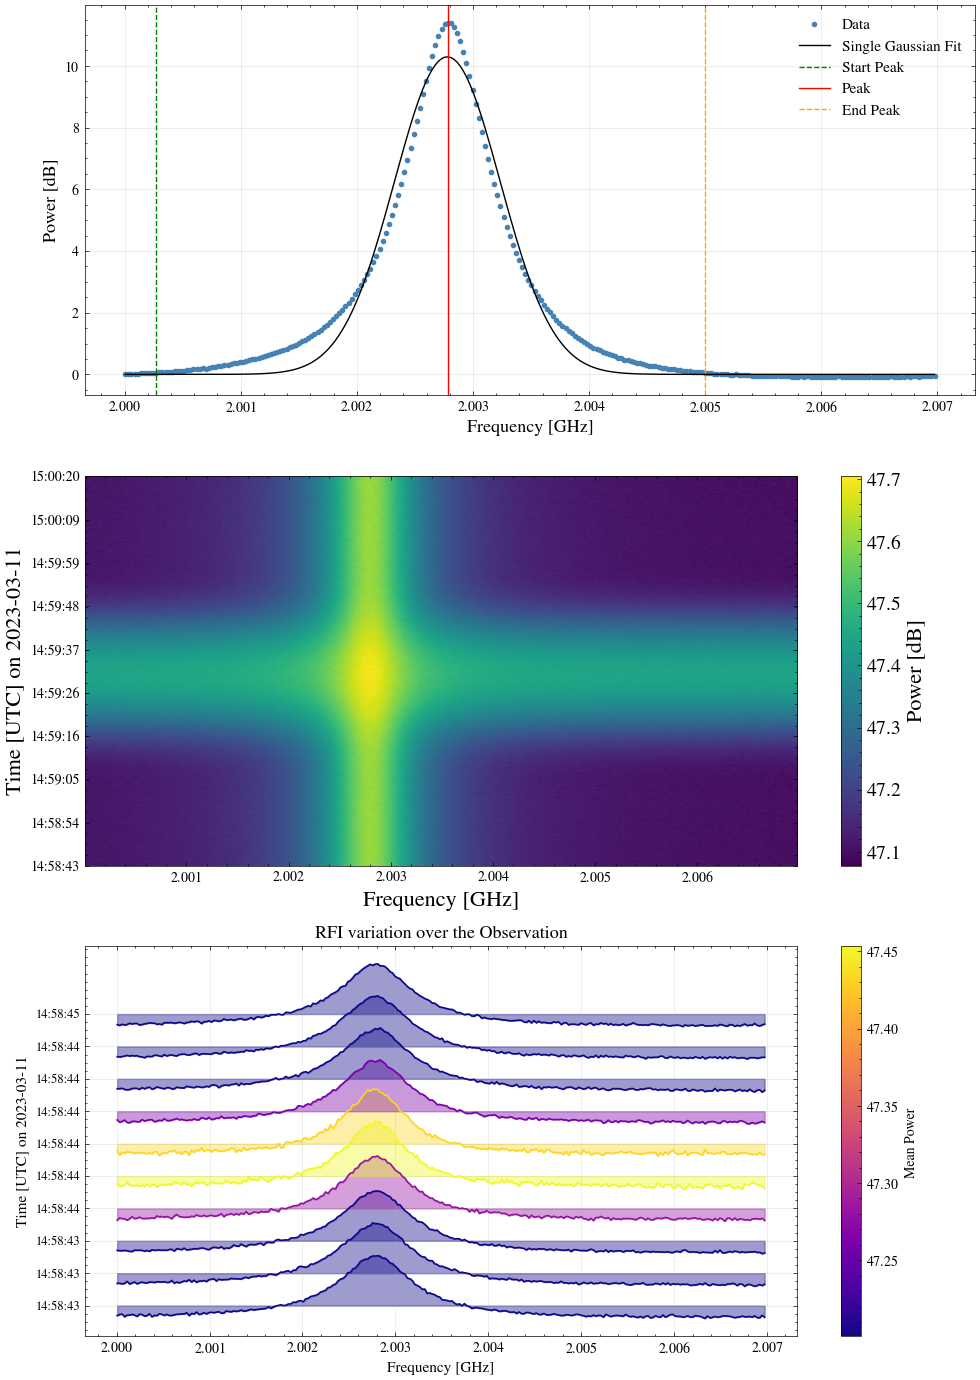

In [15]:
mask = (frequency > 2.00) & (frequency < 2.007)


fig, ax = plt.subplots(3,1, figsize=(10, 14))
plt.subplots_adjust(hspace=0.3,)

characterize_RFI_width(frequency[mask], detrended_spectrum[mask], tie=False, ax=ax[0])
waterfall_timevsfreq(time, frequency, spectrum, mask, ax=ax[1])
ridgeplot_rfi_characterization(time, frequency, spectrum, mask=mask, n_samples=10, threshold=0.05, ax=ax[2])

plt.show()

In [16]:

def ridgeplot_rfi_characterization(time_utc, frequency, spectrum, mask=None, n_samples=10, threshold=0.05, ax=None):
    """
    Create a ridge plot of spectra vs frequency and characterize RFI features
    at selected time steps.
    """
    # --- Apply mask if provided ---
    if mask is not None:
        freq = frequency[mask]
        spec = spectrum[:, mask]
    else:
        freq = frequency
        spec = spectrum

    n_time = spec.shape[0]
    idx = np.linspace(0, n_time - 1, n_samples, dtype=int)

    # Compute mean power per spectrum for colormap
    mean_power = [10 * np.log10(np.nanmean(spec[k, :]**2)) for k in idx]
    norm = plt.Normalize(min(mean_power), max(mean_power))
    colors = cm.plasma(norm(mean_power))

    #Date
    time = pd.to_datetime(time_utc, unit='s', utc=True)
    date=pd.to_datetime(time[0]).strftime('%Y-%m-%d')

    # --- Create Figure ---
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 8))

    print(f"\n === RFI CHARACTERIZATION PER TIME STEP on: {date} ===")
    print(f"Using threshold: {threshold:.3f}\n")

    for i, (k, color) in enumerate(zip(idx, colors)):
        y = spec[k, :]
        y_db = 10 * np.log10(y**2 + 1e-12)  # Convert to dB, avoid log(0)
        y_norm = (y_db - np.nanmean(y_db)) / np.nanstd(y_db)
        offset = i * 2.0

        # --- Plot ridge ---
        ax.plot(freq, y_norm + offset, color=color, lw=1.2)
        ax.fill_between(freq, offset, y_norm + offset, color=color, alpha=0.4)

        # --- RFI characterization ---
        above_threshold = np.where(y_db > threshold)[0]
        if len(above_threshold) > 0:
            start_index, end_index = above_threshold[0], above_threshold[-1]
            start_freq = freq[start_index]
            end_freq = freq[end_index]
            peak_index = np.argmax(y_db)
            peak_freq = freq[peak_index]
            peak_power = y_db[peak_index]

            delta_f = np.mean(np.diff(freq))  # channel width
            n_channels = (end_freq - start_freq) / delta_f
            bandwidth = (end_freq - start_freq) * 1e3  # GHz → MHz

            print(f"[{time[k].strftime('%H:%M:%S')}]  "
                  f"Peak: {peak_freq:.6f} GHz | Power: {peak_power:.3f} dB | "
                  f"BW: {bandwidth:.2f} MHz | Channels: {n_channels:.1f}")
        else:
            print(f"[{time[k].strftime('%H:%M:%S')}]  No RFI detected above threshold.")

    # colorbar to interoret variation
    sm=cm.ScalarMappable(cmap=cm.plasma, norm=norm)
    sm.set_array([])
    cbar=plt.colorbar(sm,ax=ax, label='Mean Power ')

    # --- Y-axis: Time Labels (UTC) ---
    n_ticks = min(10, n_samples)
    tick_positions = np.linspace(0, n_samples - 1, n_ticks, dtype=int)
    tick_labels = [time[i].strftime("%H:%M:%S") for i in tick_positions]

    ax.set_yticks(tick_positions * 2.0)
    ax.set_yticklabels(tick_labels, fontsize=9)
    ax.set_ylabel(f"Time [UTC] on {date}", fontsize=11)

    # --- X-axis ---
    ax.set_xlabel("Frequency [GHz]", fontsize=11)
    ax.set_title("RFI variation over the Observation", fontsize=13)
    ax.grid(alpha=0.3)

    plt.tight_layout()


In [17]:
n_samples = 10
n_time = spectrum.shape[0]
idx = np.linspace(0, n_time - 1, n_samples, dtype=int)

# Compute mean power per spectrum for colormap
mean_power = [10 * np.log10(np.nanmean(spectrum[k, :]**2)) for k in idx]


In [18]:
time_utc

array(['2023-03-11T14:58:43.686180592', '2023-03-11T14:58:43.839572191',
       '2023-03-11T14:58:43.992964029', '2023-03-11T14:58:44.146355629',
       '2023-03-11T14:58:44.299747229', '2023-03-11T14:58:44.453139067',
       '2023-03-11T14:58:44.606530666', '2023-03-11T14:58:44.759922504',
       '2023-03-11T14:58:44.913314104', '2023-03-11T14:58:45.066705704',
       '2023-03-11T14:58:45.220097542', '2023-03-11T14:58:45.373489141',
       '2023-03-11T14:58:45.526880741', '2023-03-11T14:58:45.680272579',
       '2023-03-11T14:58:45.833664179', '2023-03-11T14:58:45.987056017',
       '2023-03-11T14:58:46.140447617', '2023-03-11T14:58:46.293839216',
       '2023-03-11T14:58:46.447231054', '2023-03-11T14:58:46.600622654',
       '2023-03-11T14:58:46.754014254', '2023-03-11T14:58:46.907406092',
       '2023-03-11T14:58:47.060797691', '2023-03-11T14:58:47.214189529',
       '2023-03-11T14:58:47.367581129', '2023-03-11T14:58:47.520972729',
       '2023-03-11T14:58:47.674364567', '2023-03-11

In [19]:
idx

array([  0,  70, 140, 211, 281, 351, 422, 492, 562, 633])

In [20]:
time_utc[633]

np.datetime64('2023-03-11T15:00:20.783119917')

In [21]:

n_time, n_freq = spectrum.shape
n_samples = 10

chunk_size = n_time // n_samples     # 63
remainder  = n_time % n_samples      # 4

averaged_spectra = []

start = 0
for i in range(n_samples):
    # Distribute the remainder: first `remainder` chunks get +1 time sample
    extra = 1 if i < remainder else 0
    end = start + chunk_size + extra

    # Extract chunk of shape (~63, 63877)
    chunk = spectrum[start:end]

    # Average over time axis → get spectrum of shape (63877,)
    avg_spec = np.mean(chunk, axis=0)

    averaged_spectra.append(avg_spec)
    start = end

averaged_spectra = np.array(averaged_spectra)
# shape = (10, 63877)


In [22]:
# Let's assume you have a 1D array of size m*n, and you want to bin it along the time axis
# First, create some sample data. This example uses a 1D array for simplicity.
# Adapt this for your 2D (m x n) array.
data = spectrum # Example data
bin_size = 10

# Calculate the size of the array after binning.
# Use floor division to handle cases where the array size is not perfectly divisible.
binned_size = (data.size // bin_size) * bin_size

# Trim the data to be perfectly divisible by the bin size.
trimmed_data = data[:binned_size]
print(trimmed_data)
# Reshape the data into a new, higher-dimensional array where one dimension
# represents the bins.
reshaped_data = trimmed_data.reshape(-1, bin_size)
print(reshaped_data)
# Calculate the mean of each bin along the new axis.
binned_data = reshaped_data.mean(axis=1)

print(f"Original data: {data}")
print(f"Binned data (mean per 10 items): {binned_data}")


[[224.48004 224.53584 224.5948  ... 192.44615 192.17426 192.33842]
 [224.52582 224.15678 224.54155 ... 192.20285 191.98975 191.99872]
 [224.54185 224.65791 224.92969 ... 192.44676 192.51053 192.17883]
 ...
 [224.10942 224.4448  224.37529 ... 192.06285 192.05809 192.1016 ]
 [224.67734 224.87822 224.67682 ... 192.38556 192.41418 192.05182]
 [225.05374 224.48853 224.63266 ... 192.126   192.24046 192.37892]]


ValueError: cannot reshape array of size 40402918 into shape (10)

In [ ]:
binned_size

100